## Phase Neural Operator (PhaseNO)
### PhaseNO for multi-station earthquake detection and phase picking
###  - Plot results - 

##### Author: Hongyu Sun
##### Email: hongyu-sun@outlook.com


In [72]:
import os
import obspy
import numpy as np
from tqdm import tqdm
import pandas as pd
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import matplotlib
font = {'weight' : 'normal',
        'size'   : 15}
matplotlib.rc('font', **font)

In [73]:
def _detect_peaks(x, mph=None, mpd=1, threshold=0, edge='rising', kpsh=False, valley=False):

    """
    
    Detect peaks in data based on their amplitude and other features.

    Parameters
    ----------
    x : 1D array_like
        data.
        
    mph : {None, number}, default=None
        detect peaks that are greater than minimum peak height.
        
    mpd : int, default=1
        detect peaks that are at least separated by minimum peak distance (in number of data).
        
    threshold : int, default=0
        detect peaks (valleys) that are greater (smaller) than `threshold in relation to their immediate neighbors.
        
    edge : str, default=rising
        for a flat peak, keep only the rising edge ('rising'), only the falling edge ('falling'), both edges ('both'), or don't detect a flat peak (None).
        
    kpsh : bool, default=False
        keep peaks with same height even if they are closer than `mpd`.
        
    valley : bool, default=False
        if True (1), detect valleys (local minima) instead of peaks.

    Returns
    -------
    ind : 1D array_like
        indeces of the peaks in `x`.

    Modified from 
    ----------
    .. [1] http://nbviewer.ipython.org/github/demotu/BMC/blob/master/notebooks/DetectPeaks.ipynb
    

    """

    x = np.atleast_1d(x).astype('float64')
    if x.size < 3:
        return np.array([], dtype=int)
    if valley:
        x = -x
    # find indices of all peaks
    dx = x[1:] - x[:-1]
    # handle NaN's
    indnan = np.where(np.isnan(x))[0]
    if indnan.size:
        x[indnan] = np.inf
        dx[np.where(np.isnan(dx))[0]] = np.inf
    ine, ire, ife = np.array([[], [], []], dtype=int)
    if not edge:
        ine = np.where((np.hstack((dx, 0)) < 0) & (np.hstack((0, dx)) > 0))[0]
    else:
        if edge.lower() in ['rising', 'both']:
            ire = np.where((np.hstack((dx, 0)) <= 0) & (np.hstack((0, dx)) > 0))[0]
        if edge.lower() in ['falling', 'both']:
            ife = np.where((np.hstack((dx, 0)) < 0) & (np.hstack((0, dx)) >= 0))[0]
    ind = np.unique(np.hstack((ine, ire, ife)))
    # handle NaN's
    if ind.size and indnan.size:
        # NaN's and values close to NaN's cannot be peaks
        ind = ind[np.in1d(ind, np.unique(np.hstack((indnan, indnan-1, indnan+1))), invert=True)]
    # first and last values of x cannot be peaks
    if ind.size and ind[0] == 0:
        ind = ind[1:]
    if ind.size and ind[-1] == x.size-1:
        ind = ind[:-1]
    # remove peaks < minimum peak height
    if ind.size and mph is not None:
        ind = ind[x[ind] >= mph]
    # remove peaks - neighbors < threshold
    if ind.size and threshold > 0:
        dx = np.min(np.vstack([x[ind]-x[ind-1], x[ind]-x[ind+1]]), axis=0)
        ind = np.delete(ind, np.where(dx < threshold)[0])
    # detect small peaks closer than minimum peak distance
    if ind.size and mpd > 1:
        ind = ind[np.argsort(x[ind])][::-1]  # sort ind by peak height
        idel = np.zeros(ind.size, dtype=bool)
        for i in range(ind.size):
            if not idel[i]:
                # keep peaks with the same height if kpsh is True
                idel = idel | (ind >= ind[i] - mpd) & (ind <= ind[i] + mpd) \
                    & (x[ind[i]] > x[ind] if kpsh else True)
                idel[i] = 0  # Keep current peak
        # remove the small peaks and sort back the indices by their occurrence
        ind = np.sort(ind[~idel])

    return ind, x[ind]

In [74]:
Data_Path  = './waveforms/251102/'
probfolder = './results/probability_IMSB/'

stations_new = pd.read_csv('./stations.csv',sep=',')
stations_new = stations_new[2:3].reset_index(drop=True)
stations_new["st_id"]  = stations_new["id"].apply(lambda x: x.split('.')[0]+'.'+x.split('.')[1]+'.'+x.split('.')[-1])

center = (127.30, 35.55)
x_min, y_min = center[0] - 1, center[1] - 1

timestamp = datetime(2025, 11, 2, 0, 0)
itime = timestamp.strftime("%Y-%m-%dT%H:%M")
print('current at', itime)

PLOT = 1

current at 2025-11-02T00:00


## prepare station list

number of stations at  2025-11-02T00:00 :  1


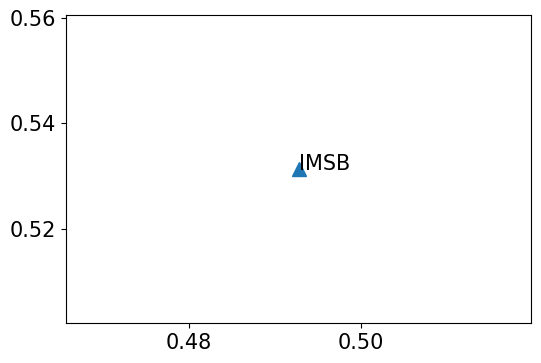

In [77]:
station_all = []
for fname in os.listdir(Data_Path):   
    if itime in fname:   
        channel_name = fname.split('.')[2]
        station_name = fname.split('.')[1]
        network_name = fname.split('.')[0]

        station_all.append(network_name+'.'+station_name+'.'+channel_name)

print('number of stations at ', itime, ': ', len(station_all))

if PLOT == 1:
    fig, ax = plt.subplots(1, 1, figsize=(6, 4))
    for i,staname in enumerate(station_all):
        sta = staname.split('.')[1]
        x = (stations_new.loc[stations_new['station'] == sta].iloc[0]['longitude']- x_min)/2
        y = (stations_new.loc[stations_new['station'] == sta].iloc[0]['latitude']- y_min)/2
        ax.plot(x,y,'^',markersize=10)
        ax.text(x,y,sta)
    ax.locator_params(axis='both', nbins=5)

networks = []
stations = []
channels = []
dis = []
ids = []
for sta in station_all:

    ch = sta.split('.')[-1]
    st = sta.split('.')[1]
    ne = sta.split('.')[0]
    channels.append(ch)
    stations.append(st)
    networks.append(ne)
    temp = stations_new.loc[stations_new['station'] == st]
    sta_select = temp.loc[temp['channel'] == ch]
    ids.append(sta_select.iloc[0]['st_id'])

    x = (stations_new.loc[stations_new['station'] == st].iloc[0]['longitude']- x_min)/2
    y = (stations_new.loc[stations_new['station'] == st].iloc[0]['latitude'] - y_min)/2
    dis.append(np.sqrt((x-0.5)**2+(y-0.5)**2))

d = {'id': ids,
        'network': networks, 
        'station': stations, 
        'channel': channels,
        'distance': dis}

df = pd.DataFrame(data=d)
df = df.sort_values(by=['distance'], ignore_index=True)

num_station = len(stations)

## read waveforms (mseed)

In [78]:
fname = []
bg_st=obspy.core.Stream()
temp = []
highpass_filter = 1
for net,sta,cha in tqdm(zip(df['network'],df['station'],df['channel'])): 
    
    fname.append(net+'.'+sta+'.'+cha+'.'+itime+'.mseed')
    mseed = obspy.read(os.path.join(Data_Path,net+'.'+sta+'.'+cha+'.'+itime+'.mseed'))
    mseed = mseed.detrend("spline", order=2, dspline=5 * mseed[0].stats.sampling_rate)
    mseed = mseed.merge(fill_value=0)
    if highpass_filter > 0:
        mseed = mseed.filter("highpass", freq=highpass_filter)
    if len(mseed) < 3:
        for r in np.arange(3-len(mseed)):
            mseed.append(mseed[0])

    bg_st += mseed[:3]

starttime = min([st.stats.starttime for st in bg_st])
endtime = max([st.stats.endtime for st in bg_st])
bg_st = bg_st.trim(starttime, endtime, pad=True, fill_value=0)
# temp = np.array(bg_st)

# split_points=list(range(3,len(bg_st),3))
# waveforms  = np.split(temp[:,:360000],split_points)

bg_st = bg_st.trim(starttime, endtime, pad=True, fill_value=0)

temp_list=[]
target_length=8640000

for tr in bg_st:
    data=tr.data
    current_len=len(data)

    if current_len >= target_length:
        temp_list.append(data[:target_length])
    else:
        pad_width=target_length-current_len
        padded_data=np.pad(data, (0, pad_width), 'constant', constant_values=0)
        temp_list.append(padded_data)

temp=np.array(temp_list)
split_points=list(range(3,len(bg_st),3))
waveforms=np.split(temp, split_points)

1it [00:04,  4.67s/it]


## read predicted probabilities and detect peaks

In [79]:
sample_rate = 100
threshold=0.9
# threshold = 0.3

p_pro_time_stream =obspy.core.Stream()
s_pro_time_stream =obspy.core.Stream()

p_idx, p_prob, s_idx, s_prob = [], [], [], []

for net,sta,cha in tqdm(zip(df['network'],df['station'],df['channel'])): 
    id = net+'.'+sta+'.'+cha+'.'+itime+'.mseed'
    st = obspy.read(probfolder+id)

    p_pro_time_stream += st[0]
    s_pro_time_stream += st[1]

    P_seq, S_seq = np.array(st[0]), np.array(st[1])
    p, p_pro =_detect_peaks(P_seq, mph=threshold, mpd=1.0*sample_rate)
    s, s_pro =_detect_peaks(S_seq, mph=threshold, mpd=1.0*sample_rate)

    p_idx.append(p)
    p_prob.append(p_pro)
    s_idx.append(s)
    s_prob.append(s_pro)

temp = np.array(p_pro_time_stream)
split_points=list(range(1,len(p_pro_time_stream),1))
p_pro_time = np.split(temp[:,:8640000],split_points)
temp = np.array(s_pro_time_stream)
split_points=list(range(1,len(s_pro_time_stream),1))
s_pro_time = np.split(temp[:,:8640000],split_points)

1it [00:03,  3.65s/it]


## Plot P/S probability trace

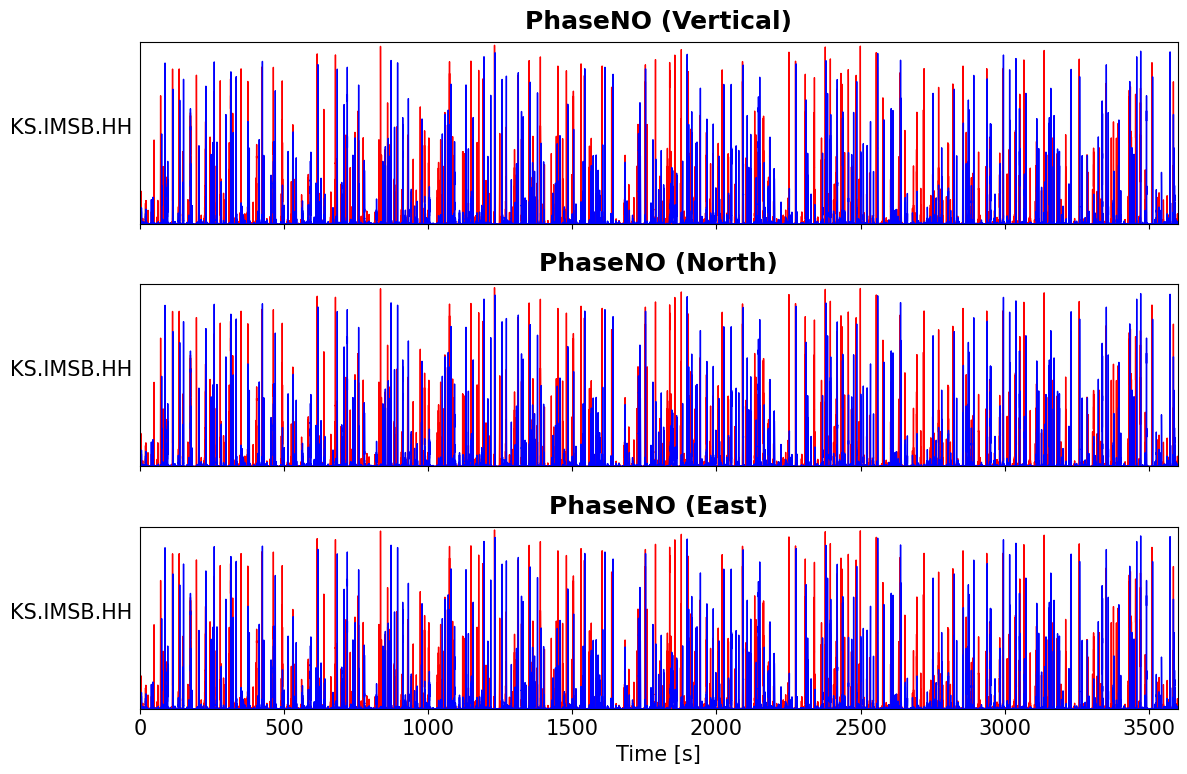

In [104]:
hour=4; minute=13; second=0
# t0 = hour*3600 + minute*60 + second; t1 = t0 + 60
t0, t1=0, 3600
barlength = 0.3
lw = 1
sampling_rate = 100
tt = np.arange(t0, t1, 1/sampling_rate)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=100)

component_indices = [2, 1, 0] # Z, N, E
component_titles = ['Vertical', 'North', 'East']

for ax, comp_idx, title in zip(axes, component_indices, component_titles):
    
    # 이 부분은 사용자의 기존 for 루프와 동일합니다.
    for ista in np.arange(num_station):
        
        p_prob_plot = p_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        s_prob_plot = s_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        
        ax.plot(tt, p_prob_plot + ista, 'r', lw=lw, alpha=1)
        ax.plot(tt, s_prob_plot + ista, 'b', lw=lw, alpha=1)
        
        ax.text(t0-450, ista+0.5, df['id'][ista], color='k')

    ax.set_title(f'PhaseNO ({title})', weight='bold', pad=10)
    ax.set_xlim([t0, t1])
    ax.set_ylim([0., 1.])
    ax.set_yticks([]) # y축 눈금은 제거

axes[2].set_xlabel('Time [s]')

plt.tight_layout()

plt.show();

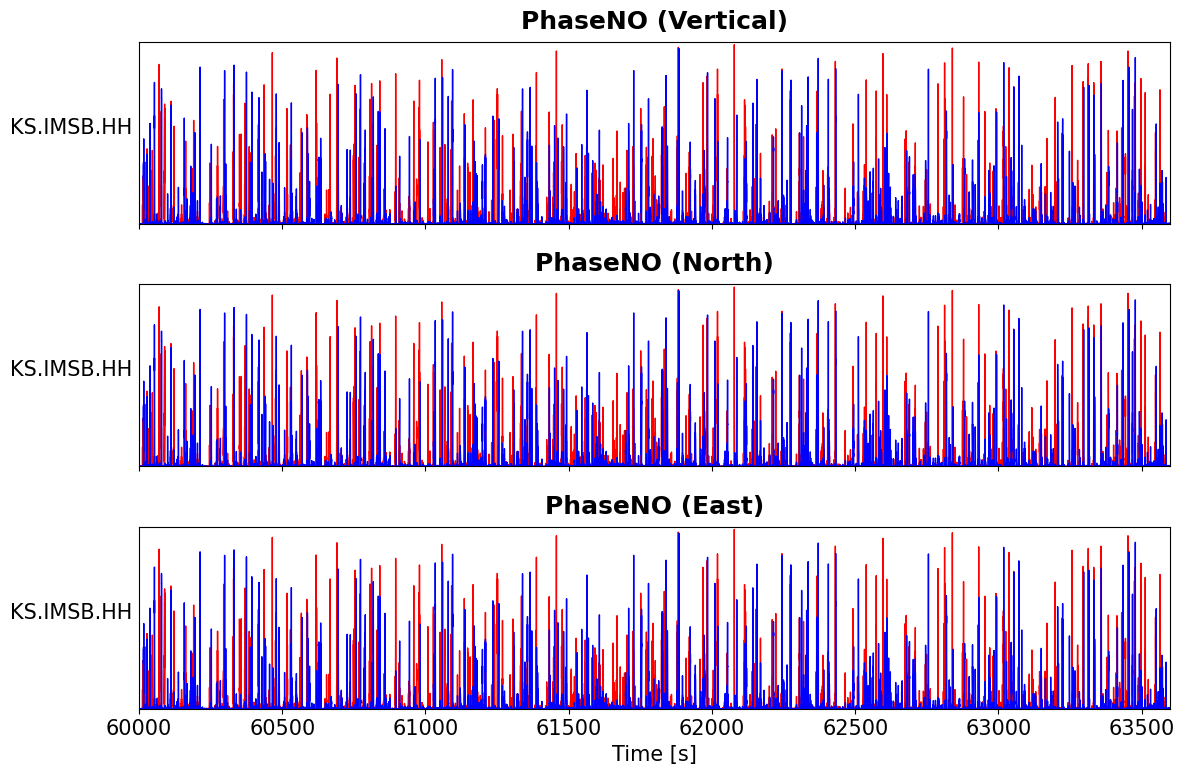

In [103]:
hour=4; minute=13; second=0
# t0 = hour*3600 + minute*60 + second; t1 = t0 + 60
t0, t1=60000, 63600
barlength = 0.3
lw = 1
sampling_rate = 100
tt = np.arange(t0, t1, 1/sampling_rate)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=100)

component_indices = [2, 1, 0] # Z, N, E
component_titles = ['Vertical', 'North', 'East']

for ax, comp_idx, title in zip(axes, component_indices, component_titles):
    
    # 이 부분은 사용자의 기존 for 루프와 동일합니다.
    for ista in np.arange(num_station):
        
        p_prob_plot = p_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        s_prob_plot = s_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        
        ax.plot(tt, p_prob_plot + ista, 'r', lw=lw, alpha=1)
        ax.plot(tt, s_prob_plot + ista, 'b', lw=lw, alpha=1)
        
        ax.text(t0-450, ista+0.5, df['id'][ista], color='k')

    ax.set_title(f'PhaseNO ({title})', weight='bold', pad=10)
    ax.set_xlim([t0, t1])
    ax.set_ylim([0., 1.])
    ax.set_yticks([]) # y축 눈금은 제거

axes[2].set_xlabel('Time [s]')

plt.tight_layout()

plt.show();

## plot one-minute waveforms and detections for all stations

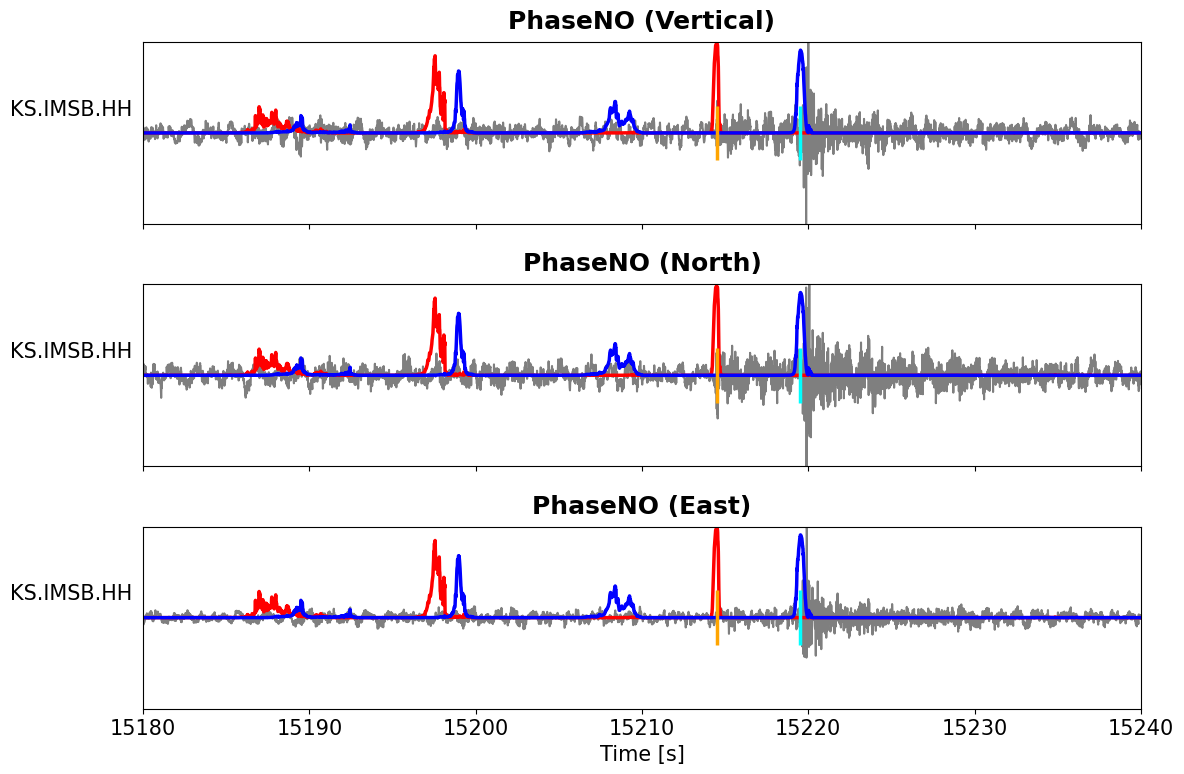

In [86]:
hour=4; minute=13; second=0
t0 = hour*3600 + minute*60 + second; t1 = t0 + 60
barlength = 0.3
lw = 2.5
sampling_rate = 100
tt = np.arange(t0, t1, 1/sampling_rate)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=100)

component_indices = [2, 1, 0] # Z, N, E
component_titles = ['Vertical', 'North', 'East']

for ax, comp_idx, title in zip(axes, component_indices, component_titles):
    
    # 이 부분은 사용자의 기존 for 루프와 동일합니다.
    for ista in np.arange(num_station):
        
        waveform = waveforms[ista][comp_idx, t0*sampling_rate:t1*sampling_rate]
        
        p_prob_plot = p_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        s_prob_plot = s_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        
        ax.plot(tt, 1*(waveform-waveform.mean())/waveform.max() + ista, 'k', alpha=0.5)
        ax.plot(tt, p_prob_plot + ista, 'red', lw=lw, alpha=1)
        ax.plot(tt, s_prob_plot + ista, 'b', lw=lw, alpha=1)
        
        ax.vlines(p_idx[ista]/100, ista-barlength, ista+barlength, 'orange', lw=lw)
        ax.vlines(s_idx[ista]/100, ista-barlength, ista+barlength, 'cyan', lw=lw)
        
        ax.text(t0-8, ista+0.2, df['id'][ista], color='k')

    ax.set_title(f'PhaseNO ({title})', weight='bold', pad=10)
    ax.set_xlim([t0, t1])
    ax.set_ylim([-1, num_station])
    ax.set_yticks([]) # y축 눈금은 제거

axes[2].set_xlabel('Time [s]')

plt.tight_layout()

plt.show();

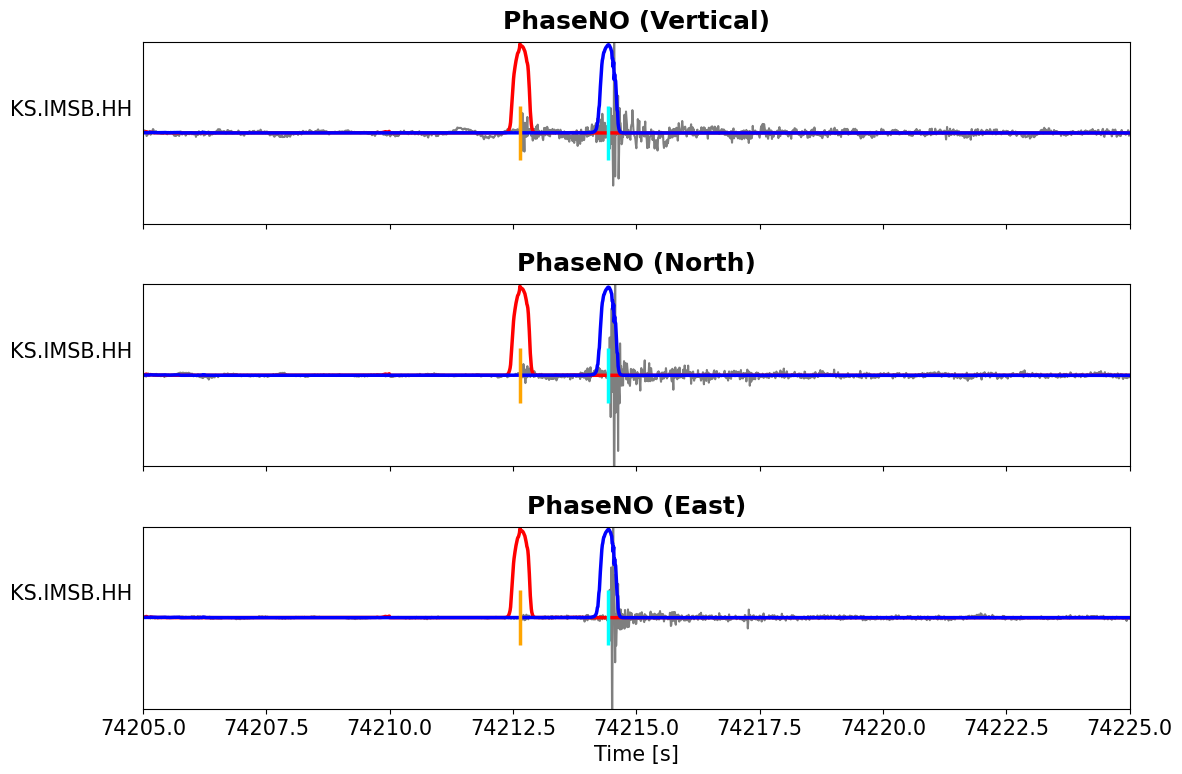

In [81]:
hour=20; minute=36; second=45
t0 = hour*3600 + minute*60 + second; t1 = t0 + 20
barlength = 0.3
lw = 2.5
sampling_rate = 100
tt = np.arange(t0, t1, 1/sampling_rate)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=100)

component_indices = [2, 1, 0] # Z, N, E
component_titles = ['Vertical', 'North', 'East']

for ax, comp_idx, title in zip(axes, component_indices, component_titles):
    
    # 이 부분은 사용자의 기존 for 루프와 동일합니다.
    for ista in np.arange(num_station):
        
        waveform = waveforms[ista][comp_idx, t0*sampling_rate:t1*sampling_rate]
        
        p_prob_plot = p_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        s_prob_plot = s_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        
        ax.plot(tt, 1*(waveform-waveform.mean())/waveform.max() + ista, 'k', alpha=0.5)
        ax.plot(tt, p_prob_plot + ista, 'red', lw=lw, alpha=1)
        ax.plot(tt, s_prob_plot + ista, 'b', lw=lw, alpha=1)
        
        ax.vlines(p_idx[ista]/100, ista-barlength, ista+barlength, 'orange', lw=lw)
        ax.vlines(s_idx[ista]/100, ista-barlength, ista+barlength, 'cyan', lw=lw)
        
        ax.text(t0-2.7, ista+0.2, df['id'][ista], color='k')

    ax.set_title(f'PhaseNO ({title})', weight='bold', pad=10)
    ax.set_xlim([t0, t1])
    ax.set_ylim([-1, num_station])
    ax.set_yticks([]) # y축 눈금은 제거

axes[2].set_xlabel('Time [s]')

plt.tight_layout()

plt.show();

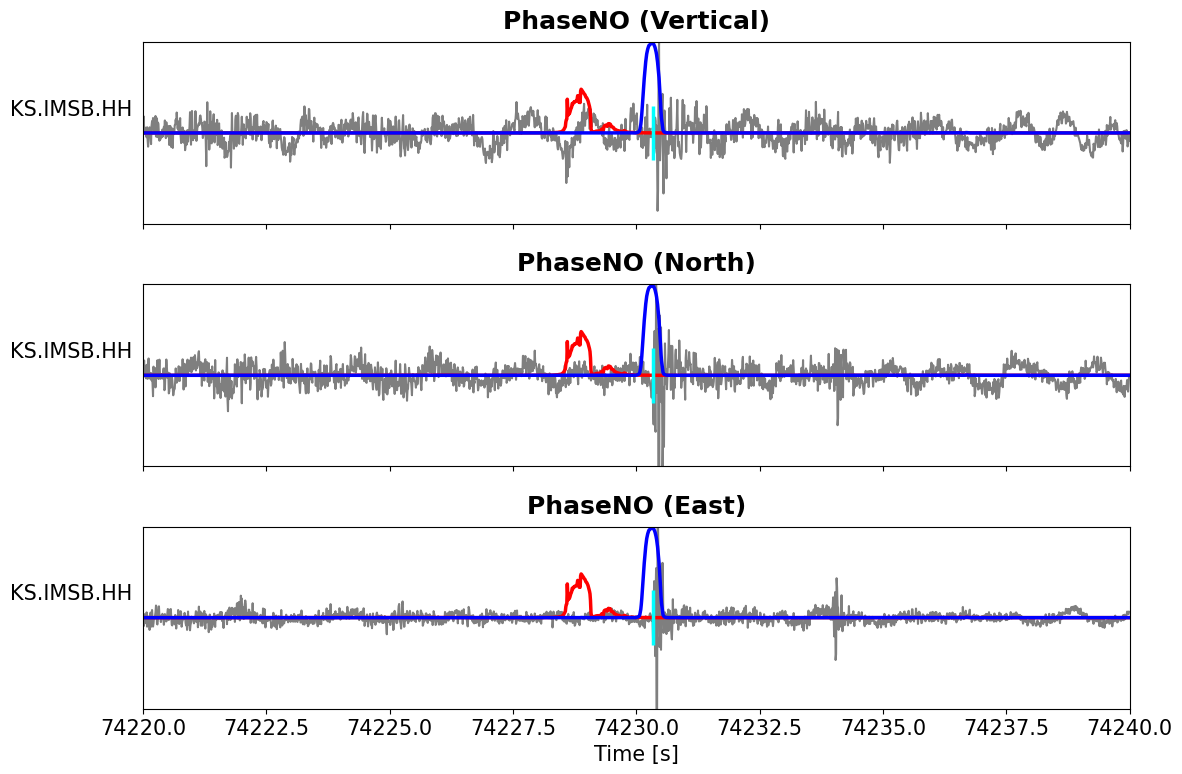

In [87]:
hour=20; minute=37; second=0
t0 = hour*3600 + minute*60 + second; t1 = t0 + 20
barlength = 0.3
lw = 2.5
sampling_rate = 100
tt = np.arange(t0, t1, 1/sampling_rate)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=100)

component_indices = [2, 1, 0] # Z, N, E
component_titles = ['Vertical', 'North', 'East']

for ax, comp_idx, title in zip(axes, component_indices, component_titles):
    
    # 이 부분은 사용자의 기존 for 루프와 동일합니다.
    for ista in np.arange(num_station):
        
        waveform = waveforms[ista][comp_idx, t0*sampling_rate:t1*sampling_rate]
        
        p_prob_plot = p_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        s_prob_plot = s_pro_time[ista][0, t0*sampling_rate:t1*sampling_rate]
        
        ax.plot(tt, 1*(waveform-waveform.mean())/waveform.max() + ista, 'k', alpha=0.5)
        ax.plot(tt, p_prob_plot + ista, 'red', lw=lw, alpha=1)
        ax.plot(tt, s_prob_plot + ista, 'b', lw=lw, alpha=1)
        
        ax.vlines(p_idx[ista]/100, ista-barlength, ista+barlength, 'orange', lw=lw)
        ax.vlines(s_idx[ista]/100, ista-barlength, ista+barlength, 'cyan', lw=lw)
        
        ax.text(t0-2.7, ista+0.2, df['id'][ista], color='k')

    ax.set_title(f'PhaseNO ({title})', weight='bold', pad=10)
    ax.set_xlim([t0, t1])
    ax.set_ylim([-1, num_station])
    ax.set_yticks([]) # y축 눈금은 제거

axes[2].set_xlabel('Time [s]')

plt.tight_layout()

plt.show();

## Check pick table

In [29]:
df_picks = pd.read_json('./results/picks_IMSB/picks_2025-11-02T00:00.json')
print(df_picks.head())

                                  id               timestamp      prob  \
0  KS.IMSB.HH.2025-11-02T00:00.mseed 2025-11-02 00:00:49.578  0.461071   
1  KS.IMSB.HH.2025-11-02T00:00.mseed 2025-11-02 00:01:12.338  0.703994   
2  KS.IMSB.HH.2025-11-02T00:00.mseed 2025-11-02 00:01:20.728  0.315710   
3  KS.IMSB.HH.2025-11-02T00:00.mseed 2025-11-02 00:01:27.358  0.321646   
4  KS.IMSB.HH.2025-11-02T00:00.mseed 2025-11-02 00:01:53.728  0.850579   

          amp type  
0  279.546234    p  
1  288.686279    p  
2  324.934448    p  
3  367.527130    p  
4  286.600128    p  


In [70]:
df_picks[df_picks["type"]=="p"][df_picks["prob"]>=0.95]

/tmp/ipykernel_127636/2522938601.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_picks[df_picks["type"]=="p"][df_picks["prob"]>=0.95]


,id,timestamp,prob,amp,type
46,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 00:13:54.898,0.975320,222.967178,p
75,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 00:20:30.288,0.981349,227.877457,p
119,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 00:31:18.088,0.957500,543.547119,p
150,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 00:39:37.328,0.971804,189.711685,p
165,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 00:41:38.908,0.976629,378.795410,p
...,...,...,...,...,...
4657,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:02:57.478,0.981388,322.724365,p
4676,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:07:17.838,0.974688,5162.206543,p
4679,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:07:51.418,0.958971,333.590057,p
4756,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:29:15.458,0.958778,462.248718,p


In [71]:
df_picks[df_picks["type"]=="s"][df_picks["prob"]>=0.95]

/tmp/ipykernel_127636/2353024116.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_picks[df_picks["type"]=="s"][df_picks["prob"]>=0.95]


,id,timestamp,prob,amp,type
5117,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 01:30:39.098,0.957126,471.667969,s
5128,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 01:34:11.798,0.970018,452.378601,s
5141,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 01:38:27.068,0.950107,332.821198,s
5223,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 02:03:13.858,0.958792,323.230774,s
5270,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 02:15:54.578,0.956632,803.355103,s
...,...,...,...,...,...
8526,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:09:43.288,0.977105,4389.966309,s
8562,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:22:55.028,0.965465,7732.257324,s
8578,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:28:52.768,0.961223,474.676453,s
8591,KS.IMSB.HH.2025-11-02T00:00.mseed,2025-11-02 22:33:39.378,0.981281,558.512634,s
